# Task 0 — Know your Data: Exploratory Data Analysis

**Project:** ML Project — Learning about Pet Adoption (Aprendizagem Automática 2026/27, FCUL)

This notebook covers **Task 0** of the official template (`AA_202627_Project.ipynb`, version updated by the professor on 26 Nov 2026): loading the data, understanding it, and **planning** the preprocessing. It does not change any value in the data and it does not train any model. Its findings are summarised for the team in [`reports/EDA_DIAGNOSTIC.md`](../reports/EDA_DIAGNOSTIC.md).

**Sections**

1. Loading the data
2. Targets: `AdoptionSpeed` and the new binary `ADOPTION`
3. Missing values and duplicates
4. Errors, typos and inconsistent values
5. High-cardinality features
6. Numerical feature distributions
7. Features vs. targets
8. Cats vs. dogs
9. Leakage risks
10. Preprocessing plan

> **Data files.** The CSV files are not in the repository (see `data/README.md`). Copy the four files supplied by the professor, unchanged, into `data/raw/` before running.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing.loader import load_petfinder, load_labels

RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
TYPE_NAMES = {1: "Dog", 2: "Cat"}
TYPE_PALETTE = {"Dog": "#4C72B0", "Cat": "#DD8452"}

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Loading the data

`pd.read_csv` does **not** read `PetFinder_dataset.csv` correctly. The file was exported from a spreadsheet and has four problems:

| Problem | Effect with `read_csv` |
|---|---|
| Every record ends with a run of `;` | Extra empty columns |
| ~60% of records are wrapped in one pair of outer quotes, with inner quotes doubled | The whole record lands in one field |
| `Description` contains unquoted commas, line breaks and `";"` fragments | Fields shift to the right |
| Some descriptions contain characters (e.g. U+0085) that Python treats as line breaks | Records are cut in two |

The loader in `src/preprocessing/loader.py` anchors each record on its **last three fields** (`PetID` is always 9 characters, then `PhotoAmt`, `AdoptionSpeed`), reads the first 20 fields from the start (handling quoted names such as `"Kiko, Mimo, Fifi"`), and keeps everything in between as `Description`. It converts numeric columns but **does not correct or drop anything**.

> **Correction to our earlier audit.** The first audit (24 Nov, in `docs/DATA_DICTIONARY.md`) used a simpler parser and reported missing values in `Type`, `Age`, `Breed1`, `AdoptionSpeed` and out-of-range codes such as `Gender = 265` or `VideoAmt = 41401`. Those were **parsing artefacts**: values from a shifted column. With the loader below every numeric field parses and every code is in its documented domain (checked in §4).

In [2]:
df = load_petfinder(RAW / "PetFinder_dataset.csv")
labels = load_labels(RAW)
breeds, colors, states = labels["breed"], labels["color"], labels["state"]

print("Main table:", df.shape)
print("Breeds:", breeds.shape, "| Colours:", colors.shape, "| States:", states.shape)
df.head(3)

Main table: (14993, 24)
Breeds: (307, 3) | Colours: (7, 2) | States: (15, 2)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,1,2,2,2,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,2,3,3,3,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,2,1,1,2,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3


In [3]:
# Sanity checks on the parse
assert df["PetID"].is_unique
assert df["PetID"].str.fullmatch(r"[0-9a-z]{9}").all()
assert df["RescuerID"].str.fullmatch(r"[0-9a-f]{32}").all()
numeric_cols = [c for c in df.columns if c not in ("Name", "RescuerID", "Description", "PetID")]
print("Non-numeric values left in numeric columns:", int(df[numeric_cols].isna().sum().sum()))
df.dtypes.to_frame("dtype").T

Non-numeric values left in numeric columns: 0


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
dtype,int64,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,int64,str,str,float64,int64


**Variable types.** The table has 14,993 listings and 24 columns:

- **Identifiers:** `PetID` (unique per listing), `RescuerID` (the person or organisation that listed the pet).
- **Free text:** `Name`, `Description`.
- **Nominal codes:** `Type`, `Breed1`, `Breed2`, `Gender`, `Color1–3`, `State`, `Vaccinated`, `Dewormed`, `Sterilized`. They are stored as integers, but the numbers carry no order: they must be encoded (e.g. one-hot) and never used as distances directly.
- **Ordinal codes:** `MaturitySize` (1 Small → 4 Extra Large), `FurLength` (1 Short → 3 Long), `Health` (1 Healthy → 3 Serious injury).
- **Counts / amounts:** `Age` (months), `Quantity`, `Fee`, `VideoAmt`, `PhotoAmt`.
- **Target:** `AdoptionSpeed` (ordinal, 0–4), from which we derive `ADOPTION`.

## 2. Targets

The updated template defines:

| `AdoptionSpeed` | Meaning | `ADOPTION` |
|---|---|---|
| 0 | Adopted the same day it was listed | 1 |
| 1 | Adopted in days 1–7 | 1 |
| 2 | Adopted in days 8–30 | 1 |
| 3 | Adopted in days 31–90 | 1 |
| 4 | **No adoption** after 100 days | 0 |

This resolves the two ambiguities we had raised about the first version (class 0 was undocumented and `ADOPTION` was written as `[0,4]`).

In [4]:
df["ADOPTION"] = (df["AdoptionSpeed"] <= 3).astype(int)
df["TypeName"] = df["Type"].map(TYPE_NAMES)

speed = df["AdoptionSpeed"].value_counts().sort_index()
adopt = df["ADOPTION"].value_counts().sort_index()
summary = pd.concat([
    pd.DataFrame({"target": "AdoptionSpeed", "class": speed.index, "count": speed.values}),
    pd.DataFrame({"target": "ADOPTION", "class": adopt.index, "count": adopt.values}),
])
summary["share"] = (summary["count"] / len(df)).round(3)
summary

,target,class,count,share
0,AdoptionSpeed,0,410,0.027
1,AdoptionSpeed,1,3090,0.206
2,AdoptionSpeed,2,4037,0.269
3,AdoptionSpeed,3,3259,0.217
4,AdoptionSpeed,4,4197,0.280
0,ADOPTION,0,4197,0.280
1,ADOPTION,1,10796,0.720


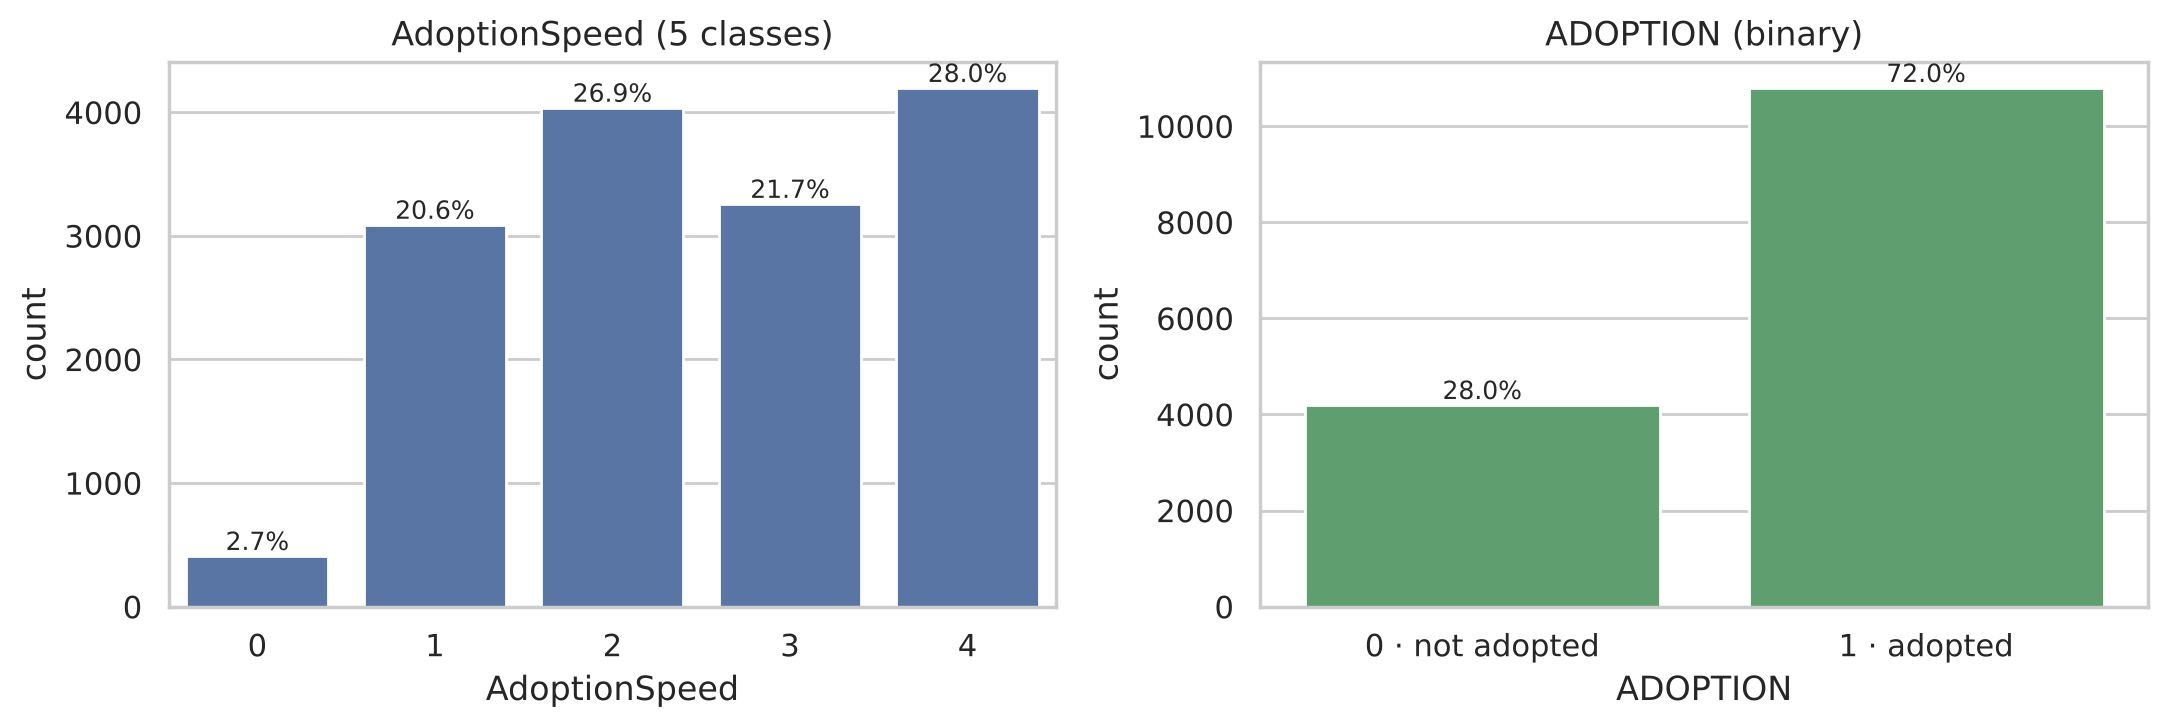

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(data=df, x="AdoptionSpeed", ax=axes[0], color="#4C72B0")
axes[0].set_title("AdoptionSpeed (5 classes)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()/len(df):.1%}", (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
sns.countplot(data=df, x="ADOPTION", ax=axes[1], color="#55A868")
axes[1].set_title("ADOPTION (binary)")
axes[1].set_xticks([0, 1], ["0 · not adopted", "1 · adopted"])
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height()/len(df):.1%}", (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
plt.tight_layout(); savefig("eda_targets"); plt.show()

In [6]:
# Majority-class baselines: the score any classifier must beat
for target in ["ADOPTION", "AdoptionSpeed"]:
    majority = df[target].value_counts(normalize=True)
    print(f"{target:14s} majority class = {majority.idxmax()}  ->  accuracy {majority.max():.3f}")

# The 3-class grouping suggested in the template: {0-1, 2-3, 4}
speed3 = df["AdoptionSpeed"].map({0: "0-1", 1: "0-1", 2: "2-3", 3: "2-3", 4: "4"})
speed3.value_counts(normalize=True).round(3).sort_index()

ADOPTION       majority class = 1  ->  accuracy 0.720
AdoptionSpeed  majority class = 4  ->  accuracy 0.280


AdoptionSpeed
0-1    0.233
2-3    0.487
4      0.280
Name: proportion, dtype: float64

**What this shows.**

- **`ADOPTION` is moderately imbalanced: 72.0% adopted vs. 28.0% not adopted.** A model that always says "adopted" already gets 72% accuracy, so accuracy alone is misleading. We should report per-class precision/recall, F1 (macro), balanced accuracy and ROC-AUC, and use **stratified** cross-validation.
- **`AdoptionSpeed` is balanced except for class 0** (same-day adoption), which has only **410 listings (2.7%)**. Classes 1–4 each hold 21–28%. A 5-class model will almost never predict class 0; per-class recall will expose this. The majority baseline is only 28%, which shows how hard the 5-class problem is.
- The template's suggested 3-class grouping {0–1, 2–3, 4} gives 23% / 49% / 28%. It absorbs the rare class 0 into class 1, which is a sensible fix for the 2.7% class.
- `AdoptionSpeed` is **ordinal**. Confusing class 1 with class 2 is a smaller mistake than confusing 1 with 4; plain accuracy ignores that. Worth discussing in Task 1.

## 3. Missing values and duplicates

In [7]:
missing = df.isna().sum().to_frame("missing")
missing["share"] = (missing["missing"] / len(df)).round(4)
missing[missing["missing"] > 0]

,missing,share
Name,1257,0.0838


In [8]:
# Codes that mean "unknown" are missing values in disguise
hidden = pd.DataFrame({
    "Breed1 = 0 (no breed)": [(df["Breed1"] == 0).sum()],
    "Vaccinated = 3 (not sure)": [(df["Vaccinated"] == 3).sum()],
    "Dewormed = 3 (not sure)": [(df["Dewormed"] == 3).sum()],
    "Sterilized = 3 (not sure)": [(df["Sterilized"] == 3).sum()],
    "MaturitySize = 0 (not specified)": [(df["MaturitySize"] == 0).sum()],
    "FurLength = 0 (not specified)": [(df["FurLength"] == 0).sum()],
    "Health = 0 (not specified)": [(df["Health"] == 0).sum()],
}, index=["rows"]).T
hidden["share"] = (hidden["rows"] / len(df)).round(3)
hidden

,rows,share
Breed1 = 0 (no breed),5,0.000
Vaccinated = 3 (not sure),1868,0.125
Dewormed = 3 (not sure),1781,0.119
Sterilized = 3 (not sure),1815,0.121
MaturitySize = 0 (not specified),0,0.000
FurLength = 0 (not specified),0,0.000
Health = 0 (not specified),0,0.000


In [9]:
names = df["Name"].fillna("").str.strip().str.lower()
placeholder = names.str.contains(r"no ?name|unnamed|not named|no-name|nameless", regex=True)
print("Empty Name:", (names == "").sum())
print("Placeholder names ('No Name Yet', 'Unnamed', ...):", placeholder.sum())
print("Names of 1-2 characters:", names.str.len().between(1, 2).sum())
print("Names that describe a group ('2 Kittens', '5 Puppies', ...):",
      names.str.contains(r"^\d+\s|kittens|puppies|pups", regex=True).sum())

Empty Name: 1257
Placeholder names ('No Name Yet', 'Unnamed', ...): 129
Names of 1-2 characters: 216
Names that describe a group ('2 Kittens', '5 Puppies', ...): 839


In [10]:
# Duplicates
print("Duplicated PetID:", df["PetID"].duplicated().sum())
cols_wo_id = [c for c in df.columns if c != "PetID"]
dup_mask = df.duplicated(subset=cols_wo_id, keep=False)
print("Rows identical in every column except PetID:", dup_mask.sum(),
      f"({df[dup_mask].groupby(cols_wo_id, dropna=False).ngroups} groups)")
df.loc[dup_mask, ["PetID", "Name", "Age", "Breed1", "RescuerID", "AdoptionSpeed"]].sort_values("RescuerID")

Duplicated PetID: 0
Rows identical in every column except PetID: 16 (8 groups)


,PetID,Name,Age,Breed1,RescuerID,AdoptionSpeed
4709,902624c4b,NaN,12,307,096cdf8460684e818fc5929c5f5462cf,2
8802,a07440416,NaN,12,307,096cdf8460684e818fc5929c5f5462cf,2
6359,5174e0542,NaN,1,266,0b65c9795c3f969870365b68c102fb81,4
12626,d0c3c032a,NaN,1,266,0b65c9795c3f969870365b68c102fb81,4
4350,0e49eebb3,NaN,1,307,5ac31b8484313639bf6240562cbbf896,4
13150,ae089cd20,NaN,1,307,5ac31b8484313639bf6240562cbbf896,4
8250,63cd0b2b3,NaN,10,197,695eed7c60628e8a051be03dfadb3092,2
11016,91c4cb54d,NaN,10,197,695eed7c60628e8a051be03dfadb3092,2
7193,c67d871e3,NaN,16,307,6a63225c99e15e616e0118ffba7e8107,4
7653,b6a16ab86,NaN,16,307,6a63225c99e15e616e0118ffba7e8107,4


**What this shows.**

- After a correct parse, **the only truly empty column is `Name`** (1,257 listings, 8.4%). Another 129 names are placeholders such as "No Name Yet", and about 840 describe a group ("2 Kittens", "5 Puppies"). An empty name is not an error: it often means a litter or a pet the rescuer did not name. It is better turned into a feature (`has_name`) than imputed.
- **Missing information is hidden in codes.** `Vaccinated`, `Dewormed` and `Sterilized` use 3 = "Not sure" for 12–13% of listings. These should stay as their own category, not be treated as numbers. `MaturitySize`, `FurLength` and `Health` never use their "not specified" code (0) in this file.
- **No duplicated `PetID`**, but **16 rows form 8 pairs that are identical in every other column** (same rescuer, same description, same outcome; none of them has a name). They are probably the same pet listed twice. If one copy ends up in a training fold and the other in a test fold, the model is tested on data it has seen. We should drop one copy of each pair (or keep pairs in the same fold).

## 4. Errors, typos and inconsistent values

We check every coded column against the domain documented in the template and the lookup tables, then look for values that are valid on their own but inconsistent with other columns.

In [11]:
domains = {
    "Type": {1, 2}, "Gender": {1, 2, 3}, "MaturitySize": {0, 1, 2, 3, 4}, "FurLength": {0, 1, 2, 3},
    "Vaccinated": {1, 2, 3}, "Dewormed": {1, 2, 3}, "Sterilized": {1, 2, 3}, "Health": {0, 1, 2, 3},
    "Color1": set(colors["ColorID"]), "Color2": set(colors["ColorID"]) | {0},
    "Color3": set(colors["ColorID"]) | {0}, "State": set(states["StateID"]),
    "Breed1": set(breeds["BreedID"]) | {0}, "Breed2": set(breeds["BreedID"]) | {0},
}
out_of_domain = {c: int((~df[c].isin(d)).sum()) for c, d in domains.items()}
pd.Series(out_of_domain, name="out-of-domain values").to_frame().T

,Type,Gender,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Color1,Color2,Color3,State,Breed1,Breed2
out-of-domain values,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [12]:
breed_type = breeds.set_index("BreedID")["Type"]
breed_name = breeds.set_index("BreedID")["BreedName"]

checks = {}
b1_type = df["Breed1"].map(breed_type)
b2_type = df["Breed2"].map(breed_type)
checks["Breed1 = 0 (no primary breed)"] = df["Breed1"] == 0
checks["Breed1 belongs to the other species"] = b1_type.notna() & (b1_type != df["Type"])
checks["Breed2 belongs to the other species"] = b2_type.notna() & (b2_type != df["Type"])
checks["Breed2 == Breed1 (redundant)"] = df["Breed2"] == df["Breed1"]
checks["Age = 0 months"] = df["Age"] == 0
checks["Age > 180 months (15 years)"] = df["Age"] > 180
checks["Sterilized = Yes but Age <= 3 months"] = (df["Sterilized"] == 1) & (df["Age"] <= 3)
checks["Gender = Mixed but Quantity = 1"] = (df["Gender"] == 3) & (df["Quantity"] == 1)
checks["Quantity > 1 but Gender not Mixed"] = (df["Quantity"] > 1) & (df["Gender"] != 3)
checks["Fee > 1000"] = df["Fee"] > 1000
checks["Name with mis-encoded characters"] = df["Name"].fillna("").str.contains("Ã|â|å|æ|ç", regex=True)

consistency = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in checks.items()}})
consistency["share"] = (consistency["rows"] / len(df)).round(4)
consistency

,rows,share
Breed1 = 0 (no primary breed),5,0.0003
Breed1 belongs to the other species,12,0.0008
Breed2 belongs to the other species,3,0.0002
Breed2 == Breed1 (redundant),1510,0.1007
Age = 0 months,179,0.0119
Age > 180 months (15 years),6,0.0004
Sterilized = Yes but Age <= 3 months,279,0.0186
Gender = Mixed but Quantity = 1,0,0.0000
Quantity > 1 but Gender not Mixed,1248,0.0832
Fee > 1000,2,0.0001


In [13]:
# Which breeds are attached to the wrong species?
wrong = df[checks["Breed1 belongs to the other species"]]
wrong.assign(Breed1Name=wrong["Breed1"].map(breed_name))[["TypeName", "Breed1", "Breed1Name", "Name"]]

,TypeName,Breed1,Breed1Name,Name
22,Cat,114,Greyhound,"Kenit, Kenot, Techit, Keyad, Owen"
1603,Cat,25,Belgian Shepherd Laekenois,Shuka
1638,Cat,21,Bearded Collie,Mi Cai 2
3783,Cat,25,Belgian Shepherd Laekenois,NaN
4233,Cat,218,Terrier,Mo-Joe
6650,Cat,15,Australian Kelpie,Munchi
7300,Cat,70,Collie,Mao Mao
8852,Cat,205,Shih Tzu,Bobby The Smiling Shih Tzu
10911,Cat,307,Mixed Breed,Kittens Encik Faisal
13686,Cat,307,Mixed Breed,Tabby


In [14]:
# Age heaping: ages are often rounded to whole years
age_12 = df.loc[df["Age"] >= 12, "Age"]
print(f"Listings aged >= 12 months whose age is a multiple of 12: {(age_12 % 12 == 0).mean():.1%}")
print("Oldest ages (months):", sorted(df["Age"].nlargest(10).tolist()))

Listings aged >= 12 months whose age is a multiple of 12: 74.6%
Oldest ages (months): [156, 168, 180, 180, 212, 212, 212, 238, 255, 255]


**What this shows.**

- **No value is outside its documented domain.** Every code in `Type`, `Gender`, colours, `State`, breeds, etc. exists in the template or the lookup tables. The "errors and typos" the template warns about are therefore **inconsistencies between columns** and **implausible values**, not invalid codes.
- **Breed ↔ species mismatches (Breed1: 12 rows, Breed2: 3 rows).** For example, cats labelled "Mixed Breed" (code 307 is the *dog* mixed breed; cats use 264–266) or dog breeds on cats. These look like data-entry errors. Fix: map cat + 307 to the cat equivalent, or set the breed to "unknown".
- **`Breed1 = 0` (5 rows):** no primary breed. Treat as unknown.
- **`Breed2 == Breed1` (1,510 rows, 10%):** a pure breed entered twice. This is not wrong, but `Breed2` adds no information there; set it to 0 before building a "mixed breed" feature.
- **Implausible ages.** 179 pets have `Age = 0`, possible for newborns. A few have `Age` up to 255 months (21 years), which is extreme for a listed pet. Ages above 12 months are **rounded to whole years in 75% of cases**, so `Age` is precise for young animals and coarse for adults. Binning `Age` (e.g. ≤2, 3–6, 7–12, 13–36, >36 months) matches this granularity.
- **Sterilised at ≤3 months (279 rows).** Unusual but possible (some shelters sterilise early). Worth flagging, not necessarily correcting.
- **`Quantity > 1` with a single gender (1,248 rows).** Not an error: a group of two males is coded `Gender = 1`. But it means `Gender` describes a group, not one animal, for 23% of listings.
- **`Fee` outliers:** up to RM 3,000 while the median is 0. The distribution is extremely skewed; a log transform or bins (free / ≤100 / >100) are safer than the raw value.
- **147 names contain mis-encoded characters** (UTF-8 text decoded twice, e.g. `â™ª`). Only relevant if we use the text.

## 5. High-cardinality features

In [15]:
card = df[["Breed1", "Breed2", "State", "Color1", "Color2", "Color3", "RescuerID", "Name", "Description", "PetID"]].nunique()
card = card.to_frame("distinct values")
card["share of rows"] = (card["distinct values"] / len(df)).round(3)
card.sort_values("distinct values", ascending=False)

,distinct values,share of rows
PetID,14993,1.000
Description,14036,0.936
Name,9060,0.604
RescuerID,5595,0.373
Breed1,176,0.012
Breed2,135,0.009
State,14,0.001
Color1,7,0.000
Color2,7,0.000
Color3,6,0.000


In [16]:
def coverage(series, levels=(0.8, 0.9, 0.95)):
    shares = series.value_counts(normalize=True).cumsum()
    return {f"{int(l*100)}%": int((shares < l).sum() + 1) for l in levels}

cov = pd.DataFrame({
    "Breed1 (all)": coverage(df["Breed1"]),
    "Breed1 (dogs)": coverage(df.loc[df["Type"] == 1, "Breed1"]),
    "Breed1 (cats)": coverage(df.loc[df["Type"] == 2, "Breed1"]),
    "State": coverage(df["State"]),
    "RescuerID": coverage(df["RescuerID"]),
}).T
cov.columns = [f"categories needed to cover {c} of rows" for c in cov.columns]
cov

,categories needed to cover 80% of rows,categories needed to cover 90% of rows,categories needed to cover 95% of rows
Breed1 (all),8,20,38
Breed1 (dogs),5,13,24
Breed1 (cats),4,8,14
State,2,4,5
RescuerID,2597,4096,4846


In [17]:
top_breeds = df["Breed1"].value_counts().head(8)
print(pd.DataFrame({"breed": top_breeds.index.map(breed_name), "rows": top_breeds.values,
                    "share": (top_breeds.values / len(df)).round(3)}).to_string(index=False))
print()
top_states = df["State"].value_counts()
print(pd.DataFrame({"state": top_states.index.map(states.set_index("StateID")["StateName"]),
                    "rows": top_states.values, "share": (top_states.values / len(df)).round(3)}).to_string(index=False))

               breed  rows  share
         Mixed Breed  5927  0.395
 Domestic Short Hair  3634  0.242
Domestic Medium Hair  1258  0.084
               Tabby   342  0.023
  Domestic Long Hair   296  0.020
             Siamese   264  0.018
             Persian   221  0.015
  Labrador Retriever   205  0.014

          state  rows  share
       Selangor  8714  0.581
   Kuala Lumpur  3845  0.256
   Pulau Pinang   843  0.056
          Johor   507  0.034
          Perak   420  0.028
Negeri Sembilan   253  0.017
         Melaka   137  0.009
          Kedah   110  0.007
         Pahang    85  0.006
     Terengganu    26  0.002
          Sabah    22  0.001
       Kelantan    15  0.001
        Sarawak    13  0.001
         Labuan     3  0.000


Rescuers: 5,595 | with a single listing: 3,783 | largest: 459 listings


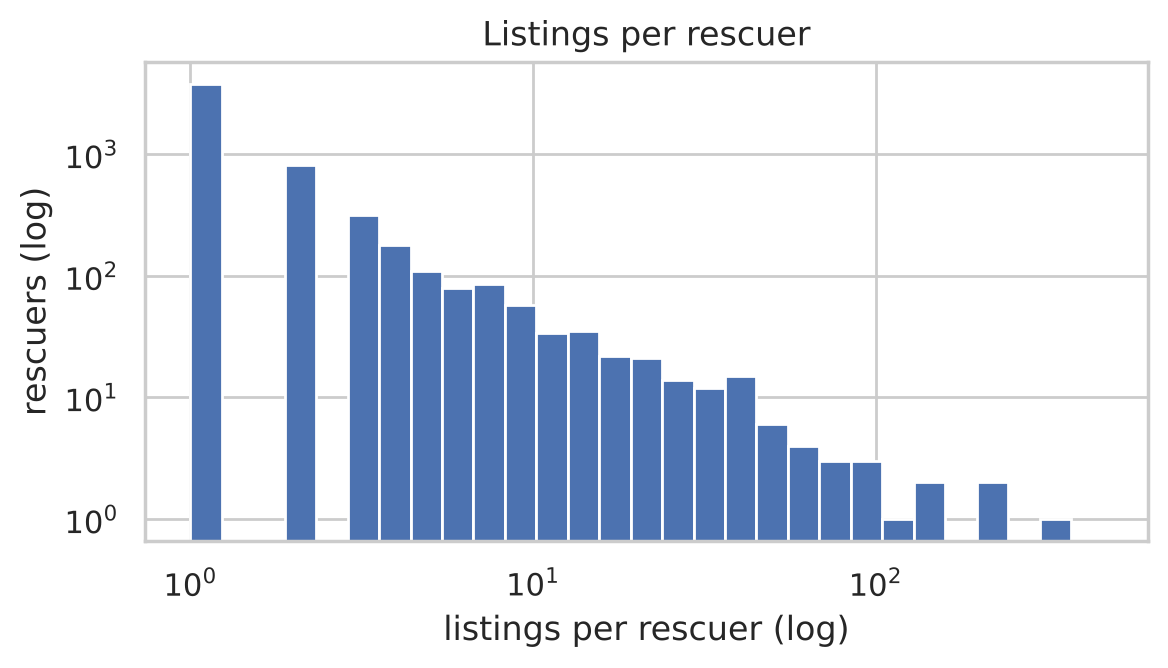

In [18]:
rescuer_count = df.groupby("RescuerID")["PetID"].transform("count")
rc = df.groupby("RescuerID").size()
print(f"Rescuers: {rc.size:,} | with a single listing: {(rc == 1).sum():,} | largest: {rc.max()} listings")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(rc, bins=np.logspace(0, np.log10(rc.max()), 30), color="#4C72B0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("listings per rescuer (log)"); ax.set_ylabel("rescuers (log)")
ax.set_title("Listings per rescuer")
plt.tight_layout(); savefig("eda_rescuer_counts"); plt.show()

**What this shows.**

- **`Breed1` has 176 distinct values, but three codes cover 72% of rows:** 307 *Mixed Breed* (dogs, 39.5%), 266 *Domestic Short Hair* (cats, 24.2%) and 265 *Domestic Medium Hair* (cats, 8.4%). 8 breeds cover 80% of rows and 38 cover 95%; the remaining ~140 codes share the last 5%. One-hot encoding all 176 codes would create many near-empty columns, which hurts distance-based models (k-NN, k-means) and Naive Bayes. Better options: **group rare breeds into "Other"**, or build simpler features such as `is_mixed_or_domestic` and `is_pure_breed`.
- **`State` has 14 values in use, but Selangor and Kuala Lumpur hold 84%** of listings. Grouping into {Selangor, Kuala Lumpur, Other} keeps most of the information.
- **`RescuerID` has 5,595 values and is an identifier, not a feature.** Using it directly would let a model memorise rescuers. But the **number of listings per rescuer** is informative (see §7), and many Kaggle participants found the same. It can be used as a constructed feature, provided it is computed carefully (see §9).
- `Name`, `Description` and `PetID` are text or identifiers. They are not usable as categorical features; at most we derive simple numbers (has name, description length).

## 6. Numerical feature distributions

In [19]:
num = ["Age", "Quantity", "Fee", "PhotoAmt", "VideoAmt"]
desc = df[num].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = df[num].skew().round(2)
desc["share of zeros"] = (df[num] == 0).mean().round(3)
desc.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,share of zeros
Age,14993.0,10.45,18.16,0.0,2.0,3.0,12.0,48.0,84.0,255.0,3.76,0.01
Quantity,14993.0,1.58,1.47,1.0,1.0,1.0,1.0,4.0,7.0,20.0,4.60,0.00
Fee,14993.0,21.26,78.41,0.0,0.0,0.0,0.0,150.0,350.0,3000.0,8.92,0.84
PhotoAmt,14993.0,3.89,3.49,0.0,2.0,3.0,5.0,10.0,19.0,30.0,2.86,0.02
VideoAmt,14993.0,0.06,0.35,0.0,0.0,0.0,0.0,0.0,2.0,8.0,9.46,0.96


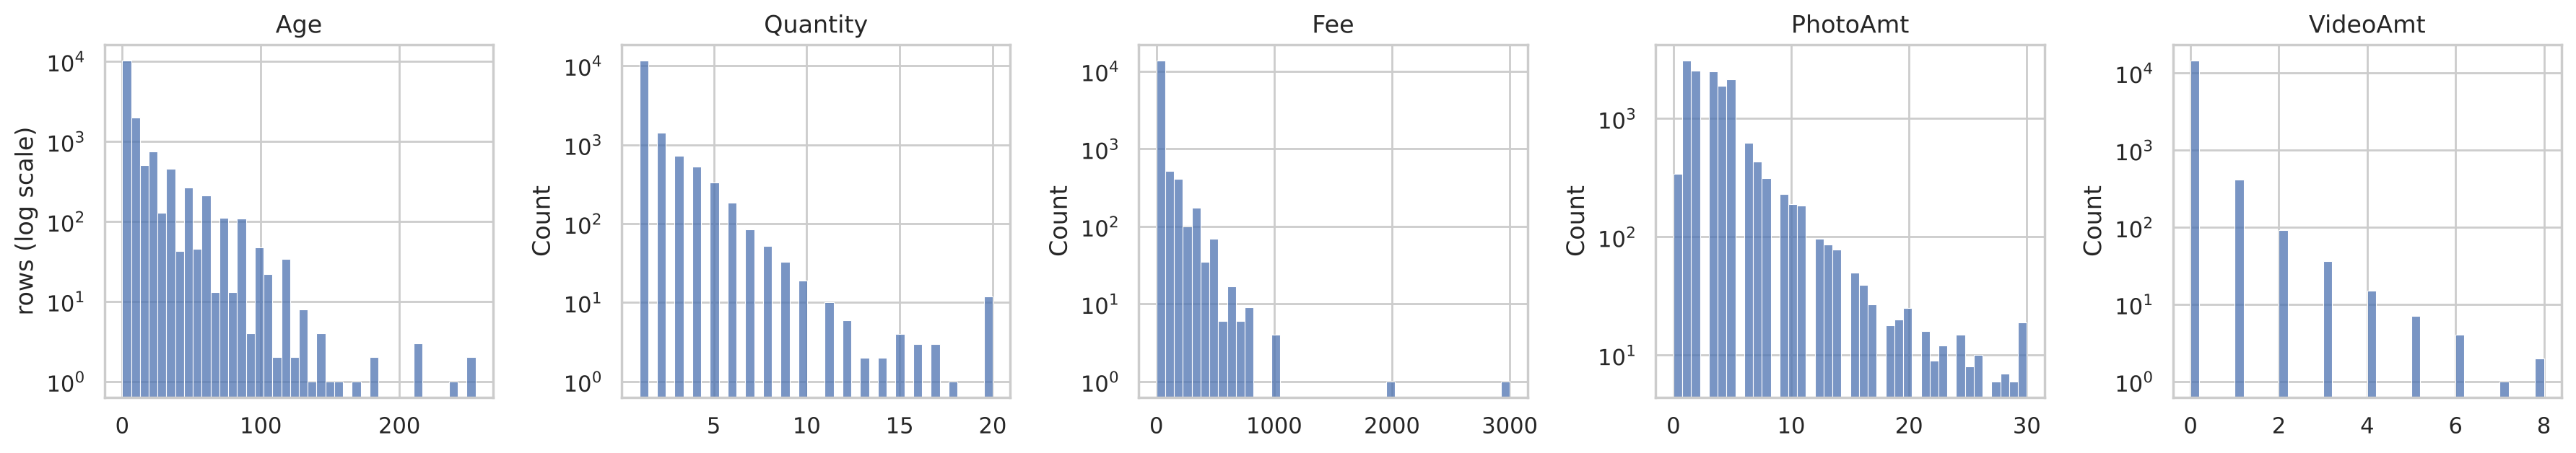

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.3))
for ax, col in zip(axes, num):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C72B0")
    ax.set_yscale("log"); ax.set_title(col); ax.set_xlabel("")
axes[0].set_ylabel("rows (log scale)")
plt.tight_layout(); savefig("eda_numeric_distributions"); plt.show()

**What this shows.** All five numeric features are **strongly right-skewed** with long tails:

- `Age`: median 3 months, 95th percentile ~5 years, maximum 21 years. Most listings are young animals.
- `Fee`: **84% of pets are free**; the rest range up to 3,000.
- `Quantity`: 77% of listings are a single pet; up to 20 in one listing.
- `PhotoAmt`: median 3; 341 listings (2.3%) have no photo.
- `VideoAmt`: **96% zeros**, max 8. Almost constant, so probably little value.

Skew matters for models that rely on distances or linear combinations (k-NN, k-means, logistic regression, SVM, MLP): a few extreme values dominate unless we **log-transform, clip or bin** before **scaling**. Decision trees and Naive Bayes on binned features are not affected.

## 7. Features vs. targets

We first measure how strongly each categorical feature is associated with each target using **Cramér's V** (0 = no association, 1 = perfect association, based on the chi-squared test of independence). Then we look at adoption rates for the most interesting features. These are **descriptive associations, not causal effects**.

In [21]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cat_features = ["Type", "Gender", "MaturitySize", "FurLength", "Vaccinated", "Dewormed",
                "Sterilized", "Health", "Color1", "Color2", "Color3", "State", "Breed1"]
assoc = pd.DataFrame({t: {c: cramers_v(df[c], df[t]) for c in cat_features}
                      for t in ["ADOPTION", "AdoptionSpeed"]}).sort_values("ADOPTION", ascending=False)
assoc["distinct values"] = df[cat_features].nunique()
assoc.round(3)

,ADOPTION,AdoptionSpeed,distinct values
Sterilized,0.210,0.163,3
Breed1,0.186,0.160,176
State,0.116,0.072,14
Vaccinated,0.105,0.097,3
FurLength,0.064,0.077,3
Dewormed,0.061,0.070,3
Gender,0.045,0.051,3
Color2,0.044,0.035,7
Color1,0.043,0.039,7
Type,0.041,0.104,2


In [22]:
df["RescuerCount"] = rescuer_count
df["DescLength"] = df["Description"].str.len()
df["HasName"] = df["Name"].notna().astype(int)
num_feats = ["Age", "Fee", "Quantity", "PhotoAmt", "VideoAmt", "RescuerCount", "DescLength", "HasName"]
rho = pd.DataFrame({
    "Spearman rho with AdoptionSpeed": [spearmanr(df[c], df["AdoptionSpeed"])[0] for c in num_feats],
    "median if adopted": [df.loc[df["ADOPTION"] == 1, c].median() for c in num_feats],
    "median if not adopted": [df.loc[df["ADOPTION"] == 0, c].median() for c in num_feats],
}, index=num_feats)
rho.round(3)

,Spearman rho with AdoptionSpeed,median if adopted,median if not adopted
Age,0.210,3.0,6.0
Fee,0.018,0.0,0.0
Quantity,0.053,1.0,1.0
PhotoAmt,-0.062,3.0,3.0
VideoAmt,-0.011,0.0,0.0
RescuerCount,-0.118,7.0,2.0
DescLength,-0.029,247.0,216.0
HasName,-0.022,1.0,1.0


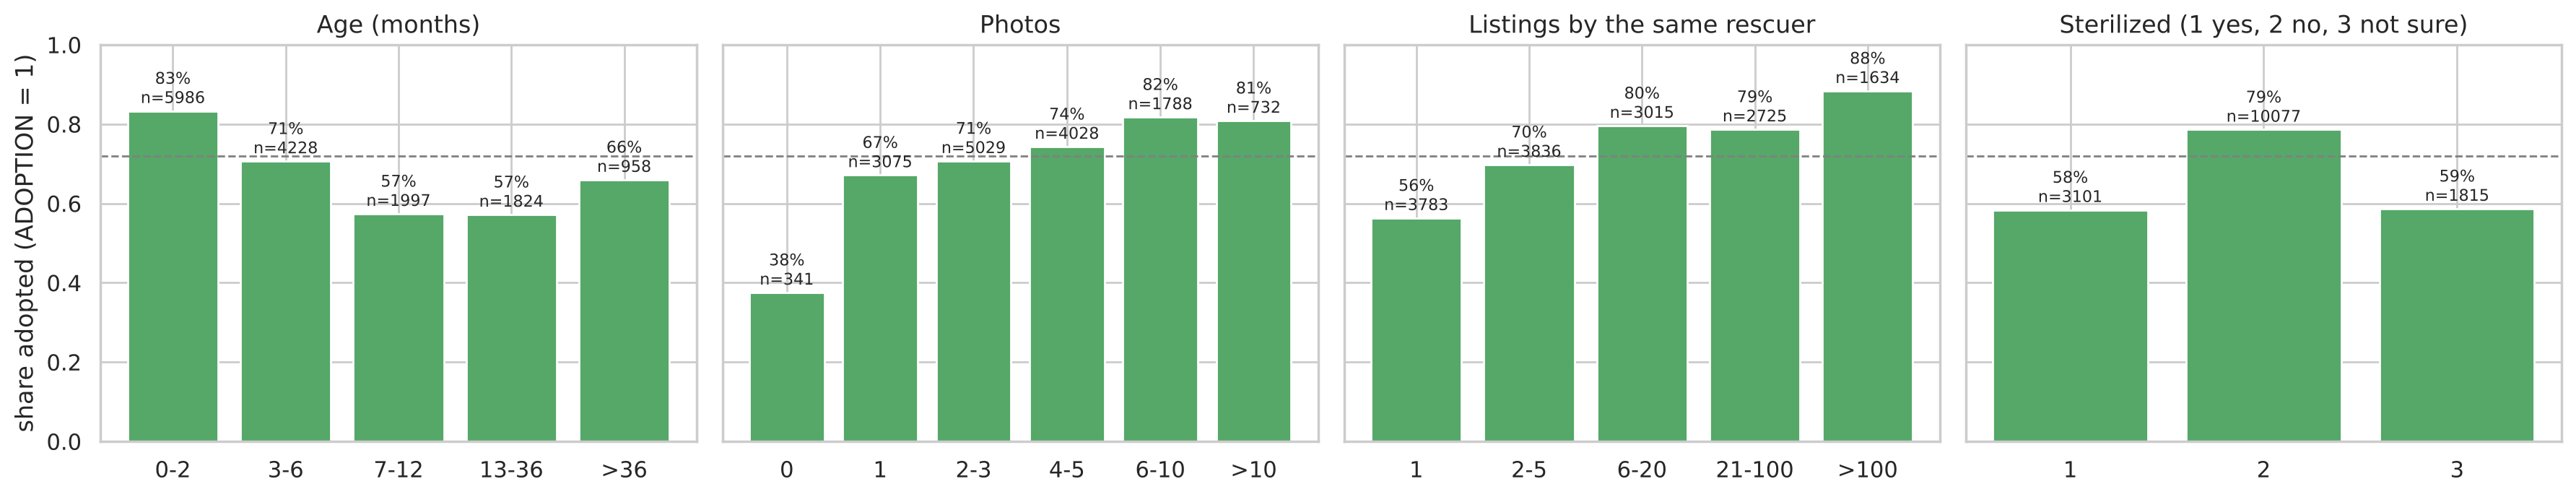

In [23]:
def rate_by(col, bins=None, labels=None):
    key = pd.cut(df[col], bins=bins, labels=labels) if bins is not None else df[col]
    return df.groupby(key, observed=True)["ADOPTION"].agg(adoption_rate="mean", rows="size")

age_bins = [-1, 2, 6, 12, 36, 300]
age_labels = ["0-2", "3-6", "7-12", "13-36", ">36"]
photo_bins = [-1, 0, 1, 3, 5, 10, 30]
photo_labels = ["0", "1", "2-3", "4-5", "6-10", ">10"]
resc_bins = [0, 1, 5, 20, 100, 500]
resc_labels = ["1", "2-5", "6-20", "21-100", ">100"]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
panels = [
    ("Age (months)", rate_by("Age", age_bins, age_labels)),
    ("Photos", rate_by("PhotoAmt", photo_bins, photo_labels)),
    ("Listings by the same rescuer", rate_by("RescuerCount", resc_bins, resc_labels)),
    ("Sterilized (1 yes, 2 no, 3 not sure)", rate_by("Sterilized")),
]
for ax, (title, tab) in zip(axes, panels):
    ax.bar(tab.index.astype(str), tab["adoption_rate"], color="#55A868")
    ax.axhline(df["ADOPTION"].mean(), color="grey", ls="--", lw=1)
    ax.set_title(title); ax.set_ylim(0, 1)
    for i, (r, n) in enumerate(zip(tab["adoption_rate"], tab["rows"])):
        ax.text(i, r + 0.02, f"{r:.0%}\nn={n}", ha="center", fontsize=8)
axes[0].set_ylabel("share adopted (ADOPTION = 1)")
plt.tight_layout(); savefig("eda_adoption_rate_by_feature"); plt.show()

In [24]:
# Is the Sterilized effect really an Age effect? Compare within age groups.
age_group = pd.cut(df["Age"], age_bins, labels=age_labels)
pd.crosstab(age_group, df["Sterilized"], values=df["ADOPTION"], aggfunc="mean").round(3) \
  .rename(columns={1: "Sterilized: yes", 2: "no", 3: "not sure"})

Sterilized,Sterilized: yes,no,not sure
Age,,,
0-2,0.662,0.857,0.650
3-6,0.618,0.739,0.589
7-12,0.575,0.605,0.501
13-36,0.531,0.651,0.552
>36,0.633,0.739,0.611


**What this shows.**

- **No single feature is strongly associated with either target.** The largest Cramér's V is about 0.2. Adoption depends on many weak signals, which is consistent with the Kaggle competition, where the best honest models were far from perfect. We should expect modest scores and focus on careful evaluation rather than headline numbers.
- **Age is the clearest signal.** 83% of pets aged 0–2 months are adopted, against 57% for 7–36 months (Spearman ρ = 0.21 with `AdoptionSpeed`: older → slower).
- **Sterilized and Vaccinated look "backwards":** non-sterilised pets are adopted *more* often (79% vs. 58%). A natural suspicion is age (non-sterilised pets are mostly very young), but the table split by age shows the gap **persists in every age group** (e.g. 86% vs. 66% at 0–2 months). So age does not explain it. We have no tested explanation yet (one hypothesis: sterilised, vaccinated animals are more often listed by organised shelters with a fee and stricter adoption conditions). This is a clear case where an association must not be read as a cause, and a good point for the critical discussion.
- **Photos help:** listings with no photo are adopted only 38% of the time, against 82% for 6+ photos.
- **Rescuer activity matters:** pets from rescuers with a single listing are adopted 56% of the time, against 88% for rescuers with more than 100 listings. Large, organised rescuers seem to place animals more reliably.
- **`Breed1`'s V (0.19) is partly inflated** by its 176 categories with many tiny cells; the grouped version should be re-checked after preprocessing.
- `Fee`, `VideoAmt`, `Quantity` and description length show almost no monotonic relation with `AdoptionSpeed` (|ρ| ≤ 0.06).

## 8. Cats vs. dogs

Task 1.3 asks for specialised cat and dog models, so we need to know how the two populations differ.

In [25]:
print(df["TypeName"].value_counts().to_string(), "\n")
ct = pd.crosstab(df["TypeName"], df["AdoptionSpeed"], normalize="index").round(3)
ct["ADOPTION rate"] = df.groupby("TypeName")["ADOPTION"].mean().round(3)
ct

TypeName
Dog    8132
Cat    6861 



AdoptionSpeed,0,1,2,3,4,ADOPTION rate
TypeName,,,,,,
Cat,0.035,0.241,0.273,0.191,0.260,0.740
Dog,0.021,0.176,0.266,0.240,0.297,0.703


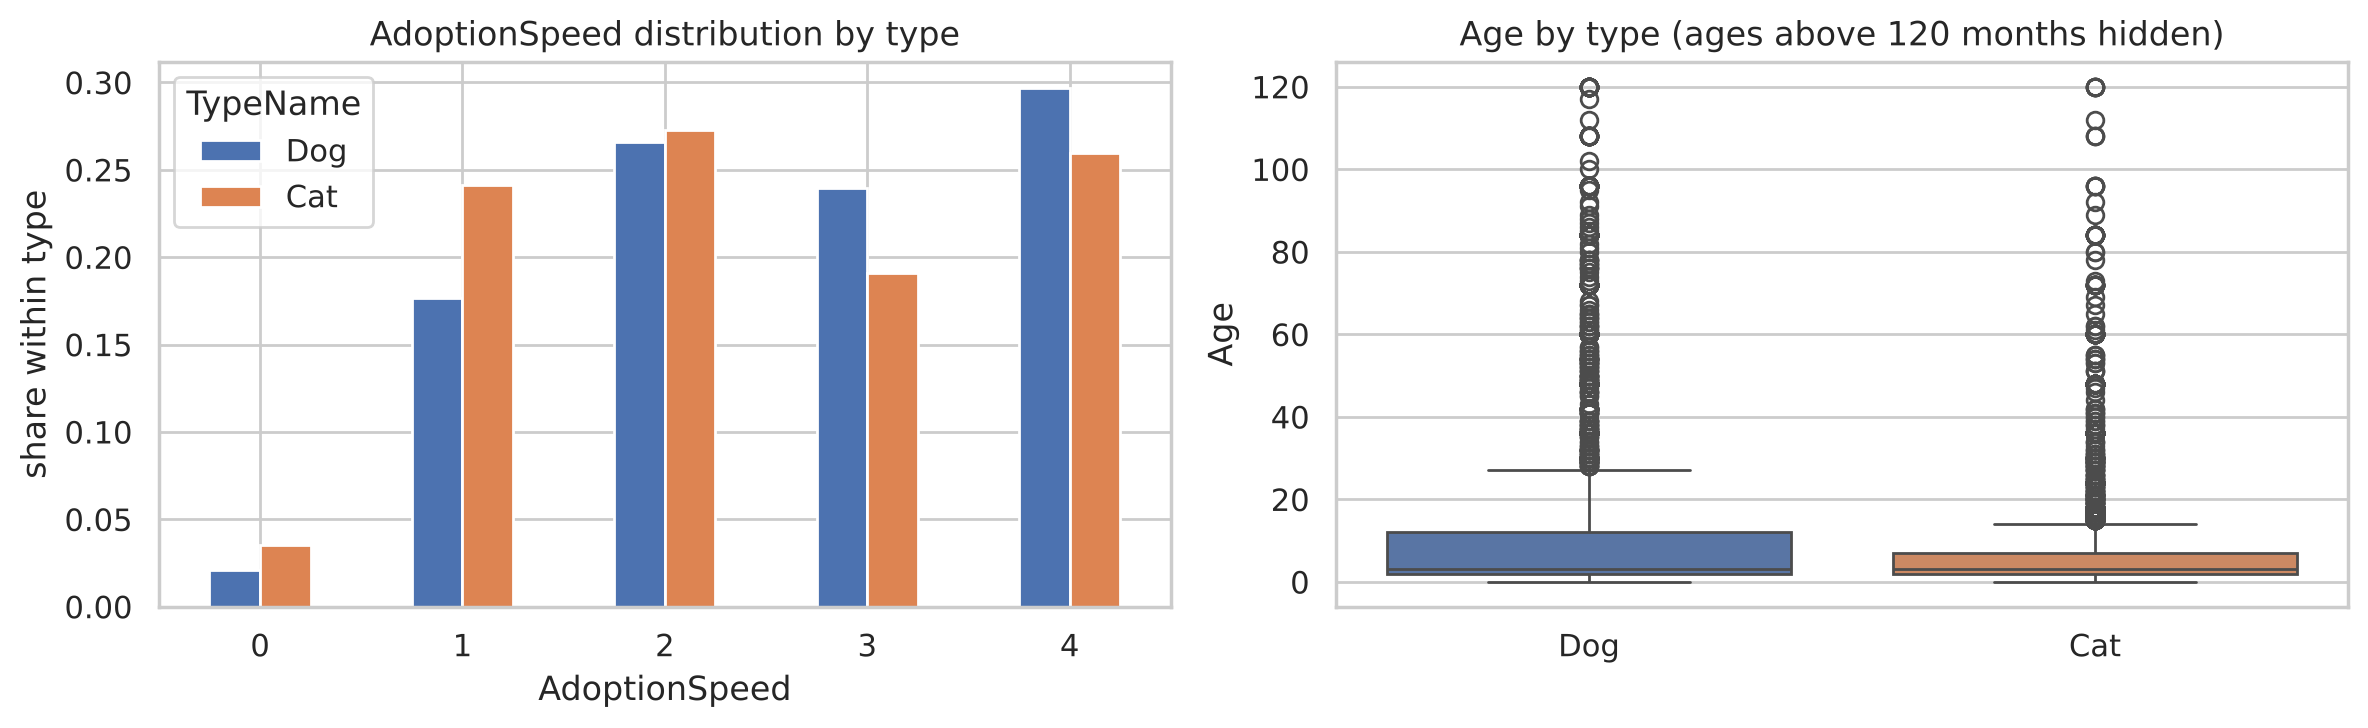

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sp = pd.crosstab(df["TypeName"], df["AdoptionSpeed"], normalize="index").T
sp[["Dog", "Cat"]].plot.bar(ax=axes[0], color=[TYPE_PALETTE["Dog"], TYPE_PALETTE["Cat"]], rot=0)
axes[0].set_title("AdoptionSpeed distribution by type"); axes[0].set_ylabel("share within type")
sns.boxplot(data=df[df["Age"] <= 120], x="TypeName", y="Age", hue="TypeName",
            palette=TYPE_PALETTE, ax=axes[1], order=["Dog", "Cat"])
axes[1].set_title("Age by type (ages above 120 months hidden)"); axes[1].set_xlabel("")
plt.tight_layout(); savefig("eda_cats_vs_dogs"); plt.show()

In [27]:
by_type = df.groupby("TypeName").apply(lambda g: pd.Series({
    "listings": len(g),
    "distinct Breed1": g["Breed1"].nunique(),
    "mixed / domestic breed": g["Breed1"].isin([307, 264, 265, 266]).mean(),
    "median age (months)": g["Age"].median(),
    "age <= 3 months": (g["Age"] <= 3).mean(),
    "vaccinated = yes": (g["Vaccinated"] == 1).mean(),
    "sterilized = yes": (g["Sterilized"] == 1).mean(),
    "fee > 0": (g["Fee"] > 0).mean(),
    "long fur": (g["FurLength"] == 3).mean(),
    "size: medium": (g["MaturitySize"] == 2).mean(),
    "no photo": (g["PhotoAmt"] == 0).mean(),
}), include_groups=False).T
by_type.round(3)

TypeName,Cat,Dog
listings,6861.000,8132.000
distinct Breed1,68.000,116.000
mixed / domestic breed,0.757,0.728
median age (months),3.000,3.000
age <= 3 months,0.533,0.528
vaccinated = yes,0.290,0.480
sterilized = yes,0.183,0.227
fee > 0,0.166,0.146
long fur,0.065,0.047
size: medium,0.609,0.753


In [28]:
assoc_type = pd.DataFrame({
    name: {c: cramers_v(g[c], g["ADOPTION"]) for c in cat_features if c not in ("Type",)}
    for name, g in df.groupby("TypeName")
}).sort_values("Dog", ascending=False)
assoc_type.round(3)

,Cat,Dog
Sterilized,0.206,0.210
Breed1,0.154,0.204
State,0.110,0.140
FurLength,0.053,0.076
Vaccinated,0.131,0.074
Color1,0.055,0.061
Color2,0.057,0.055
Gender,0.040,0.053
MaturitySize,0.028,0.041
Health,0.025,0.041


**What this shows.**

- **54% dogs, 46% cats.** Both groups are large enough to train separate models (Task 1.3).
- **Cats are adopted somewhat more and faster.** 74% of cats are adopted vs. 70% of dogs, and cats are more often adopted in the first week (class 0 + 1: 28% vs. 20%). Dogs are more often in classes 3 and 4.
- **The populations are similar in age** (median 3 months for both) and in the share of mixed/domestic breeds (~73–76%). Dogs are more often vaccinated (48% vs. 29%) and more often medium-sized (75% vs. 61%).
- **The breed vocabulary is disjoint:** dog and cat breeds use different codes. In a joint model, `Breed1` already carries `Type` implicitly. In separate models, each one only needs to deal with its own breeds, which reduces cardinality.
- **Feature associations differ by species** (table above). For example, `Vaccinated` and `Dewormed` are more associated with adoption for cats (V = 0.13 and 0.09) than for dogs (0.07 and 0.03), while `Breed1`, `State` and `FurLength` matter more for dogs. This supports the hypothesis behind Task 1.3 that specialised models *could* help, but whether they actually do is an empirical question for the cross-validation experiments.

## 9. Leakage risks

| Risk | Why it matters | Mitigation |
|---|---|---|
| **Same rescuer in train and test** | 5,595 rescuers; the largest has 459 listings with very similar descriptions and outcomes. A random split lets the model recognise rescuers. | Consider `GroupKFold` by `RescuerID` (or at least compare it with stratified k-fold to measure the optimism). |
| **`RescuerCount` computed on all data** | Counting listings per rescuer over the whole file uses test rows. | Compute it inside each training fold, or argue it is known at listing time (the rescuer's history). Document the choice. |
| **Duplicate listings (8 pairs)** | One copy in train, one in test = memorised answer. | Drop duplicates before splitting. |
| **`ADOPTION` derived from `AdoptionSpeed`** | Using one as a feature for the other is target leakage. | Never include either target as a feature. |
| **Preprocessing fitted on all data** | Scalers, imputers, binning thresholds and category groupings learned on the full data leak test information. | Fit them inside a scikit-learn `Pipeline` within cross-validation. |

## 10. Preprocessing plan

These are **proposals** for the team to discuss; none has been applied to the data. Decisions will be recorded in `docs/DECISIONS.md`.

| # | Step | Applies to |
|---|---|---|
| P1 | Load with `src/preprocessing/loader.py`; create `ADOPTION = 1` if `AdoptionSpeed` ∈ {0,1,2,3}, else 0. | All |
| P2 | Drop one copy of each of the 8 duplicate pairs. | All |
| P3 | Fix breed inconsistencies: `Breed1 = 0` → unknown; breed of the wrong species → "unknown" (or the species' mixed code); `Breed2 = Breed1` → 0. | All |
| P4 | Keep "Not sure" (3) as its own category in `Vaccinated`, `Dewormed`, `Sterilized`. | All |
| P5 | Group rare categories: `Breed1` → top-k breeds + "Other" (or `is_mixed_or_domestic`); `State` → {Selangor, Kuala Lumpur, Other}. | All |
| P6 | Handle skew: `log1p` or bins for `Age`, `Fee`, `Quantity`, `PhotoAmt`; consider dropping `VideoAmt` (96% zeros). | Distance/linear models, clustering |
| P7 | Construct simple features: `HasName`, `DescLength`, `IsMixedBreed`, `NumColors`, `RescuerCount` (computed within training folds). | All |
| P8 | Drop identifiers and raw text from the feature matrix: `PetID`, `RescuerID`, `Name`, `Description`. | All |
| P9 | One-hot encode nominal features; keep `MaturitySize`, `FurLength`, `Health` as ordinal; scale numeric features (`StandardScaler`) inside a `Pipeline`. | Task 1 (k-NN, LR, SVM, MLP), Task 2 |
| P10 | Stratified (and possibly grouped by `RescuerID`) k-fold cross-validation; report macro-F1, balanced accuracy, per-class recall, confusion matrices, ROC-AUC (binary). | Task 1 |
| P11 | Class imbalance: start with `class_weight="balanced"` where available; resampling (e.g. SMOTE) only if the team approves it, since `imbalanced-learn` is outside the core syllabus. | Task 1 |
| P12 | Task 2: cluster **adopted pets only** (`ADOPTION = 1`), without `AdoptionSpeed` in the features; use `AdoptionSpeed` afterwards as the external label (e.g. adjusted Rand index) and silhouette as the internal metric. | Task 2 |